# Sepsis: минимальный сценарий survpm

Журнал → DFG → модель → сеть Петри → генерация → восстановление → прогноз → все метрики библиотеки.
Подробные пояснения — в `petri_net_time_estimation_sepsis.ipynb`.

Нужны `pip install -e "survpm[metrics]"`, `log-distance-measures` (см. README) и graphviz (`brew install graphviz`).

In [1]:
import sys, warnings
from pathlib import Path
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dima/survpm/src/survpm").is_dir())
sys.path.insert(0, str(ROOT / "dima/survpm/src"))
warnings.filterwarnings("ignore")
import survpm
from survpm.metrics.crossval import CrossValidator, summarize

PATH = ROOT / "Med_Eremina/Sepsis Cases - Event Log_grouped.csv"

## 1. Журнал и train/test

Правила задаются один раз в `prepare`; дальше начало и конец процесса берутся из журнала.

In [2]:
log = survpm.datasets.load_sepsis_log(PATH).prepare({"starts": ["Registration"], "terminals": ["Discharge"]})
train, test = log.split(seed=1)
print("train/test объектов:", len(train.case_ids), len(test.case_ids))

train/test объектов: 840 210


## 2. DFG

совпадение с PM4Py DFG: 1.0


,state,issue


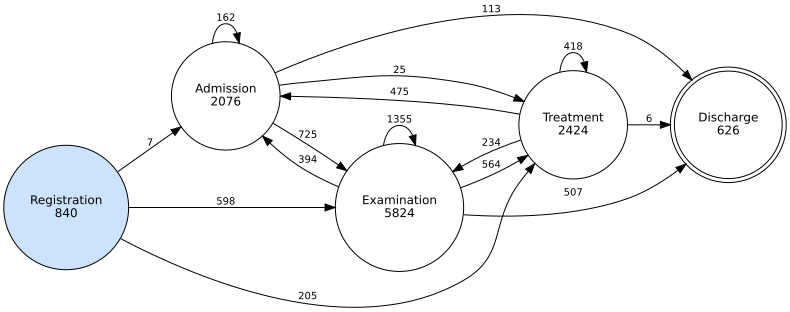

In [3]:
viz = survpm.GraphvizVisualizer()
network = survpm.discover(train)
print("совпадение с PM4Py DFG:", survpm.compare_networks(network, survpm.discover(train, survpm.Pm4pyBackend()))["f1"])
display(network.validate())
viz.plot_dfg(train)

## 3. Модель

,src,dst,n_completed,n_visits,rate,p,mean_days
0,Registration,Treatment,205,840,13.285089,0.253086,0.019050
1,Registration,Examination,598,840,38.753578,0.738272,0.019050
2,Registration,Admission,7,840,0.453637,0.008642,0.019050
3,Treatment,Examination,234,1212,3.048758,0.206531,0.067743
4,Treatment,Admission,475,1212,6.188719,0.419241,0.067743
5,Treatment,Treatment,418,1212,5.446073,0.368932,0.067743
6,Treatment,Discharge,6,1212,0.078173,0.005296,0.067743
7,Examination,Treatment,564,2912,0.165345,0.200000,1.209589
8,Examination,Examination,1355,2912,0.397240,0.480496,1.209589
9,Examination,Discharge,507,2912,0.148635,0.179787,1.209589


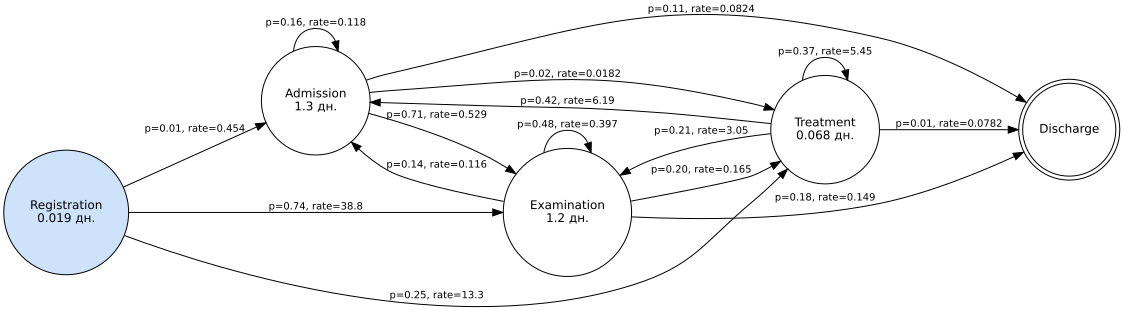

In [4]:
model = survpm.ProcessModel(network).fit(train)
display(model.edges_table())
model.plot()

## 4. Сеть Петри (сеть состояний с местом CENS) и для сравнения Inductive Miner

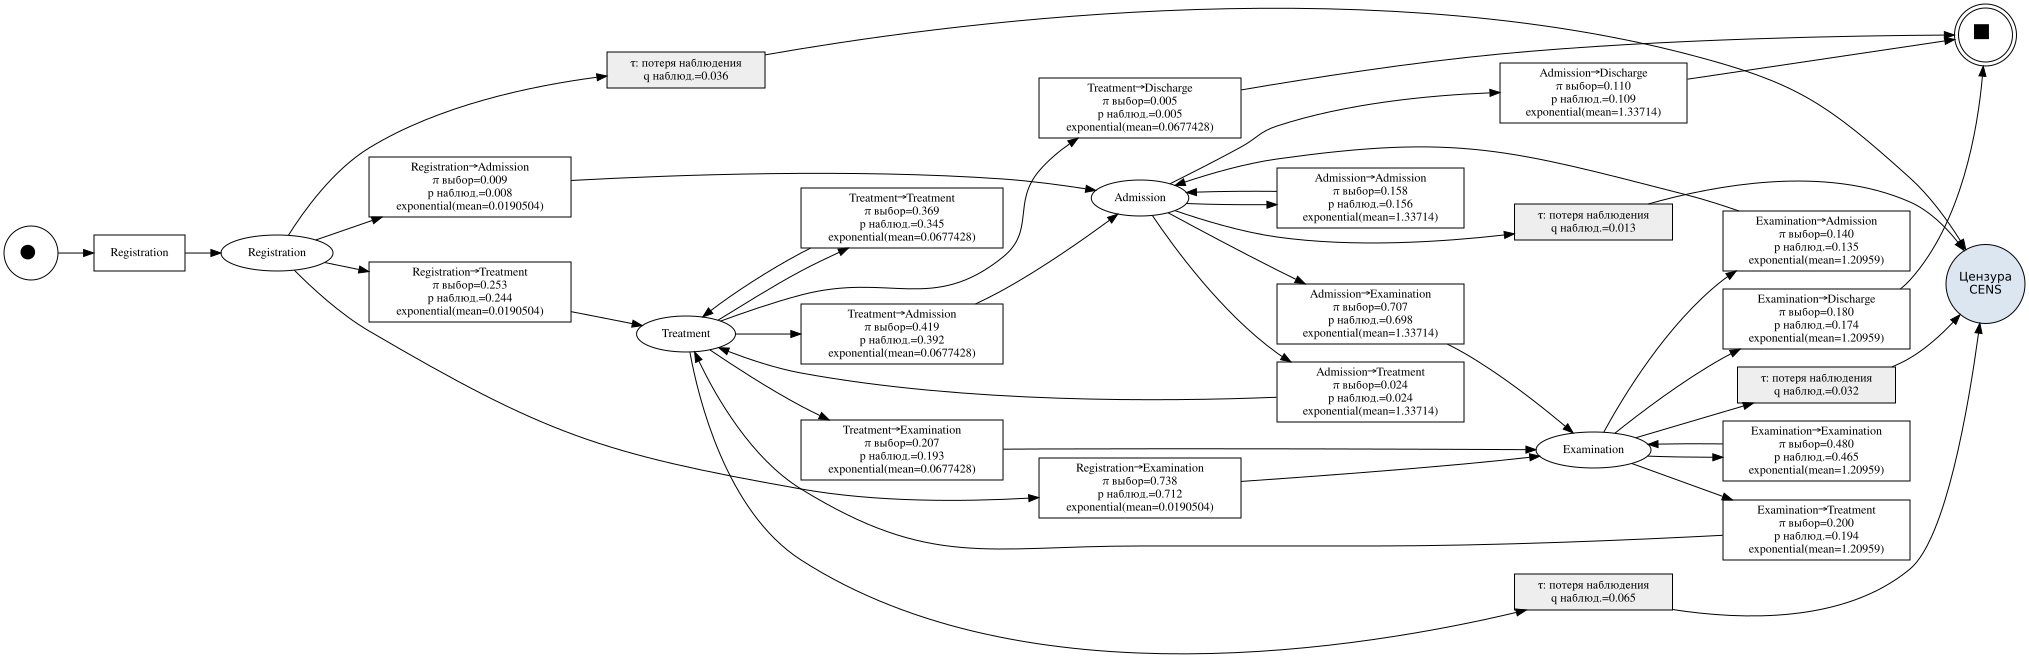

In [5]:
model.plot("petri")

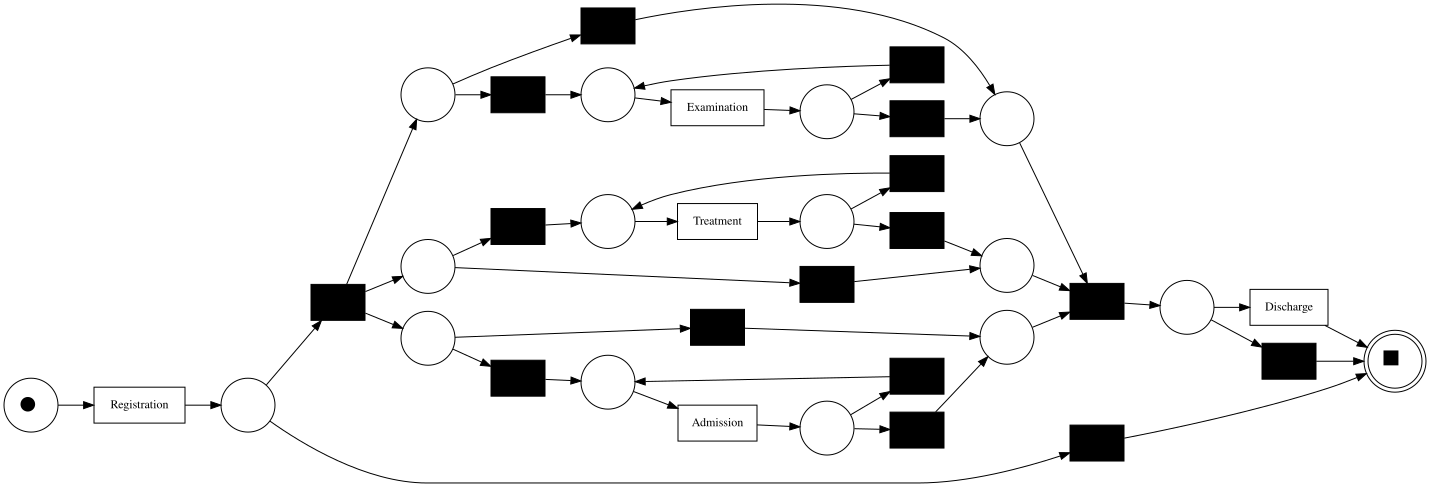

In [6]:
import pm4py
from survpm.adapters import to_pm4py_log
pm4py.visualization.petri_net.visualizer.apply(*pm4py.discover_petri_net_inductive(to_pm4py_log(train.events)))

## 5. Генерация

In [7]:
synthetic = survpm.Simulator(model, seed=7).run(survpm.ObjectStream.from_log(train, prefix="syn-"), horizon=60)
display(synthetic.events.head(8))
display(synthetic.observation.reason.replace("", "Discharge").value_counts())

,case_id,activity,timestamp
0,syn-XJ,Registration,2013-11-07 07:18:29+00:00
1,syn-XJ,Treatment,2013-11-07 07:18:42.642910761+00:00
2,syn-XJ,Admission,2013-11-07 13:25:20.114937330+00:00
3,syn-XJ,Treatment,2013-11-08 14:01:36.302941409+00:00
4,syn-XJ,Treatment,2013-11-08 14:49:26.050582139+00:00
5,syn-XJ,Admission,2013-11-08 15:57:25.557071715+00:00
6,syn-XJ,Examination,2013-11-09 14:24:59.071075370+00:00
7,syn-XJ,Examination,2013-11-09 18:03:51.748165483+00:00


reason
Discharge    840
Name: count, dtype: int64

## 6. Восстановление сети и интенсивностей по синтетике

In [8]:
recovered = survpm.discover(synthetic.prepare(log.rules))
print({k: v for k, v in survpm.compare_networks(network, recovered).items() if k in ("precision", "recall", "f1")})
refit = survpm.ProcessModel(network).fit(synthetic)
display(model.edges_table()[["src", "dst", "rate"]].merge(
    refit.edges_table()[["src", "dst", "rate"]], on=["src", "dst"], suffixes=("_model", "_recovered")))

{'precision': 1.0, 'recall': 1.0, 'f1': 1.0}


,src,dst,rate_model,rate_recovered
0,Registration,Treatment,13.285089,14.502583
1,Registration,Examination,38.753578,39.914768
2,Registration,Admission,0.453637,0.457289
3,Treatment,Examination,3.048758,3.123675
4,Treatment,Admission,6.188719,6.169014
5,Treatment,Treatment,5.446073,5.503152
6,Treatment,Discharge,0.078173,0.058753
7,Examination,Treatment,0.165345,0.158302
8,Examination,Examination,0.397240,0.386285
9,Examination,Discharge,0.148635,0.151537


## 7. Прогноз test-объекта на момент второго события

In [9]:
case_id = test.case_ids[0]
as_of = test.events.loc[test.events.case_id == case_id, "timestamp"].iloc[1]
forecaster = survpm.Forecaster(model, n_paths=1000, seed=1)
display(forecaster.survival(test, as_of, [1., 3., 7., 14., 30.], case_id=case_id))
display(forecaster.hazard(test, as_of, [1., 3., 7., 14., 30.], case_id=case_id))
print(forecaster.expected_time(test, as_of, horizon=30., case_id=case_id))
display(survpm.Router(model, seed=1).run(test, case_id, as_of, horizon=30.).events)  # один путь

,horizon,survival,cdf
0,1.0,0.838,0.162
1,3.0,0.658,0.342
2,7.0,0.397,0.603
3,14.0,0.178,0.822
4,30.0,0.029,0.971


,horizon,outcome,hazard
0,1.0,Discharge,0.162000
1,3.0,Discharge,0.107399
2,7.0,Discharge,0.099164
3,14.0,Discharge,0.078805
4,30.0,Discharge,0.052317


{'restricted_mean_time': 7.611355516046552, 'probability_unfinished': 0.029}


,case_id,activity,timestamp
0,A,Examination,2014-10-22 09:27:00+00:00
1,A,Admission,2014-10-22 14:04:54.551300070+00:00
2,A,Examination,2014-10-22 21:15:52.273790303+00:00
3,A,Discharge,2014-10-24 00:20:20.083515129+00:00


## 8. Метрики на test

Все метрики библиотеки одной таблицей `level, model, metric, value`: NLL (v2) и уровни 1–4 —
process mining, стохастические, временные, правдоподобие. Список имён — `survpm.available_metrics()`.

In [10]:
metrics = survpm.evaluate(model, test, "all")
metrics.pivot_table(index=["level", "metric"], values="value", sort=False, dropna=False)

replaying log with TBR, completed traces ::   0%|          | 0/86 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 86/86 [00:00<00:00, 2370.60it/s]

replaying log with TBR, completed traces ::   0%|          | 0/14 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 14/14 [00:00<00:00, 4212.66it/s]

replaying log with TBR, completed traces ::   0%|          | 0/312 [00:00<?, ?it/s]

replaying log with TBR, completed traces ::  60%|█████▉    | 186/312 [00:00<00:00, 1858.89it/s]

replaying log with TBR, completed traces :: 100%|██████████| 312/312 [00:00<00:00, 1963.43it/s]

replaying log with TBR, completed traces ::   0%|          | 0/100 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 100/100 [00:00<00:00, 2495.21it/s]

value
level  metric                     
nll    nll_per_interval   0.954653
       nll_per_trace      7.005337
       fitness_token           NaN
       precision_token         NaN
       generalization          NaN
...                            ...
level4 km_l1_days              NaN
       logrank_statistic       NaN
       logrank_p               NaN
       ibs                     NaN
       unseen_share       0.000000

[105 rows x 1 columns]

5-fold CV по целым трассам: naive против censor-aware, сеть состояний против Inductive Miner.

In [11]:
cv = CrossValidator(k=5).add_metrics("all").run(log, progress=None)
survpm.long_format(cv).pivot_table(index=["level", "metric"], columns="model", values="value", sort=False)

replaying log with TBR, completed traces ::   0%|          | 0/96 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 96/96 [00:00<00:00, 3084.00it/s]

replaying log with TBR, completed traces ::   0%|          | 0/14 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 14/14 [00:00<00:00, 5970.54it/s]

replaying log with TBR, completed traces ::   0%|          | 0/96 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 96/96 [00:00<00:00, 1156.16it/s]

... (92 outputs left out)

replaying log with TBR, completed traces :: 100%|██████████| 96/96 [00:00<00:00, 2293.27it/s]

replaying log with TBR, completed traces ::   0%|          | 0/96 [00:00<?, ?it/s]

replaying log with TBR, completed traces :: 100%|██████████| 96/96 [00:00<00:00, 1167.70it/s]

model                            state_net  inductive       naive  \
level  metric                                                       
level1 fitness_token              1.000000   1.000000         NaN   
       precision_token            0.611548   0.597629         NaN   
       generalization             0.772367   0.858046         NaN   
       simplicity                 0.523810   0.672727         NaN   
level2 entropic_relevance              NaN        NaN   12.276900   
       uemsc                           NaN        NaN    0.130869   
       emd                             NaN        NaN    0.270239   
level3 temporal_deviation_share        NaN        NaN    0.137143   
       cfld                            NaN        NaN    0.292827   
       ngram_3                         NaN        NaN    0.208655   
       cycle_time_emd                  NaN        NaN   27.863810   
       absolute_event_emd              NaN        NaN  247.687662   
       edge_ks                         NaN        NaN    0.404897   
       km_sup                          NaN        NaN    0.201434   
       km_l1_days                      NaN        NaN    1.634147   
       logrank_statistic               NaN        NaN    1.046924   
       logrank_p                       NaN        NaN    0.367755   
       ibs                             NaN        NaN    0.212121   
level4 unseen_share                    NaN        NaN    0.000000   
       nll_per_interval                NaN        NaN    1.068034   
       nll_per_trace                   NaN        NaN    7.666512   

model                            censor_aware  train_log  
level  metric                                             
level1 fitness_token                      NaN        NaN  
       precision_token                    NaN        NaN  
       generalization                     NaN        NaN  
       simplicity                         NaN        NaN  
level2 entropic_relevance           12.276900        NaN  
       uemsc                         0.130869        NaN  
       emd                           0.270239        NaN  
level3 temporal_deviation_share      0.137143       0.14  
       cfld                          0.292827        NaN  
       ngram_3                       0.208655        NaN  
       cycle_time_emd               27.863810        NaN  
       absolute_event_emd          247.686375        NaN  
       edge_ks                       0.404884        NaN  
       km_sup                        0.201394        NaN  
       km_l1_days                    1.634186        NaN  
       logrank_statistic             1.047254        NaN  
       logrank_p                     0.367669        NaN  
       ibs                           0.212121        NaN  
level4 unseen_share                  0.000000        NaN  
       nll_per_interval              1.068021        NaN  
       nll_per_trace                 7.666431        NaN

Модель можно сохранить и загрузить: `model.save("sepsis.pkl")`, `survpm.ProcessModel.load("sepsis.pkl")`.